# P04: 30-Day Hospital Readmission Risk Prediction

In [6]:
import pandas as pd
#dataframe
df = pd.read_csv("diabetic_data.csv")
#head of the DF
print(df.head())       # First 5 rows
print(df.shape)        # Number of rows and columns
print(df.info())       # Column names and data types
print(df.describe())   # Statistical summary


   encounter_id  patient_nbr             race  gender      age weight  \
0       2278392      8222157        Caucasian  Female   [0-10)      ?   
1        149190     55629189        Caucasian  Female  [10-20)      ?   
2         64410     86047875  AfricanAmerican  Female  [20-30)      ?   
3        500364     82442376        Caucasian    Male  [30-40)      ?   
4         16680     42519267        Caucasian    Male  [40-50)      ?   

   admission_type_id  discharge_disposition_id  admission_source_id  \
0                  6                        25                    1   
1                  1                         1                    7   
2                  1                         1                    7   
3                  1                         1                    7   
4                  1                         1                    7   

   time_in_hospital  ... citoglipton insulin  glyburide-metformin  \
0                 1  ...          No      No                   No

In [7]:
# Binary target: 1 = readmitted within 30 days; 0 = readmitted after 30 days or not readmitted
df['readmitted'] = (df['readmitted'] == '<30').astype(int)

print(df['readmitted'].value_counts().sort_index())


readmitted
0    90409
1    11357
Name: count, dtype: int64


In [ ]:
# Preserve high-missingness categorical clinical fields as an explicit category.
# This retains potentially useful information while distinguishing unavailable data.
missing_category_columns = ['weight', 'payer_code', 'medical_specialty']
df[missing_category_columns] = df[missing_category_columns].replace('?', 'Unknown').fillna('Unknown')

# Death (11, 19, 20, 21) and hospice (13, 14) dispositions cannot lead to readmission.
unviable_dispositions = [11, 13, 14, 19, 20, 21]
df = df.loc[~df['discharge_disposition_id'].isin(unviable_dispositions)].copy()

print(f'Retained encounters: {len(df):,}')
print(df[missing_category_columns].eq('Unknown').sum())


length_of_stay_group: chi-square p-value = 5.466e-55
lab_procedure_quartile: chi-square p-value = 2.09e-11
emergency_visit_group: chi-square p-value = 1.691e-110
change: chi-square p-value = 5.144e-09
A1Cresult: chi-square p-value = 3.055e-09
max_glu_serum: chi-square p-value = 0.0001684


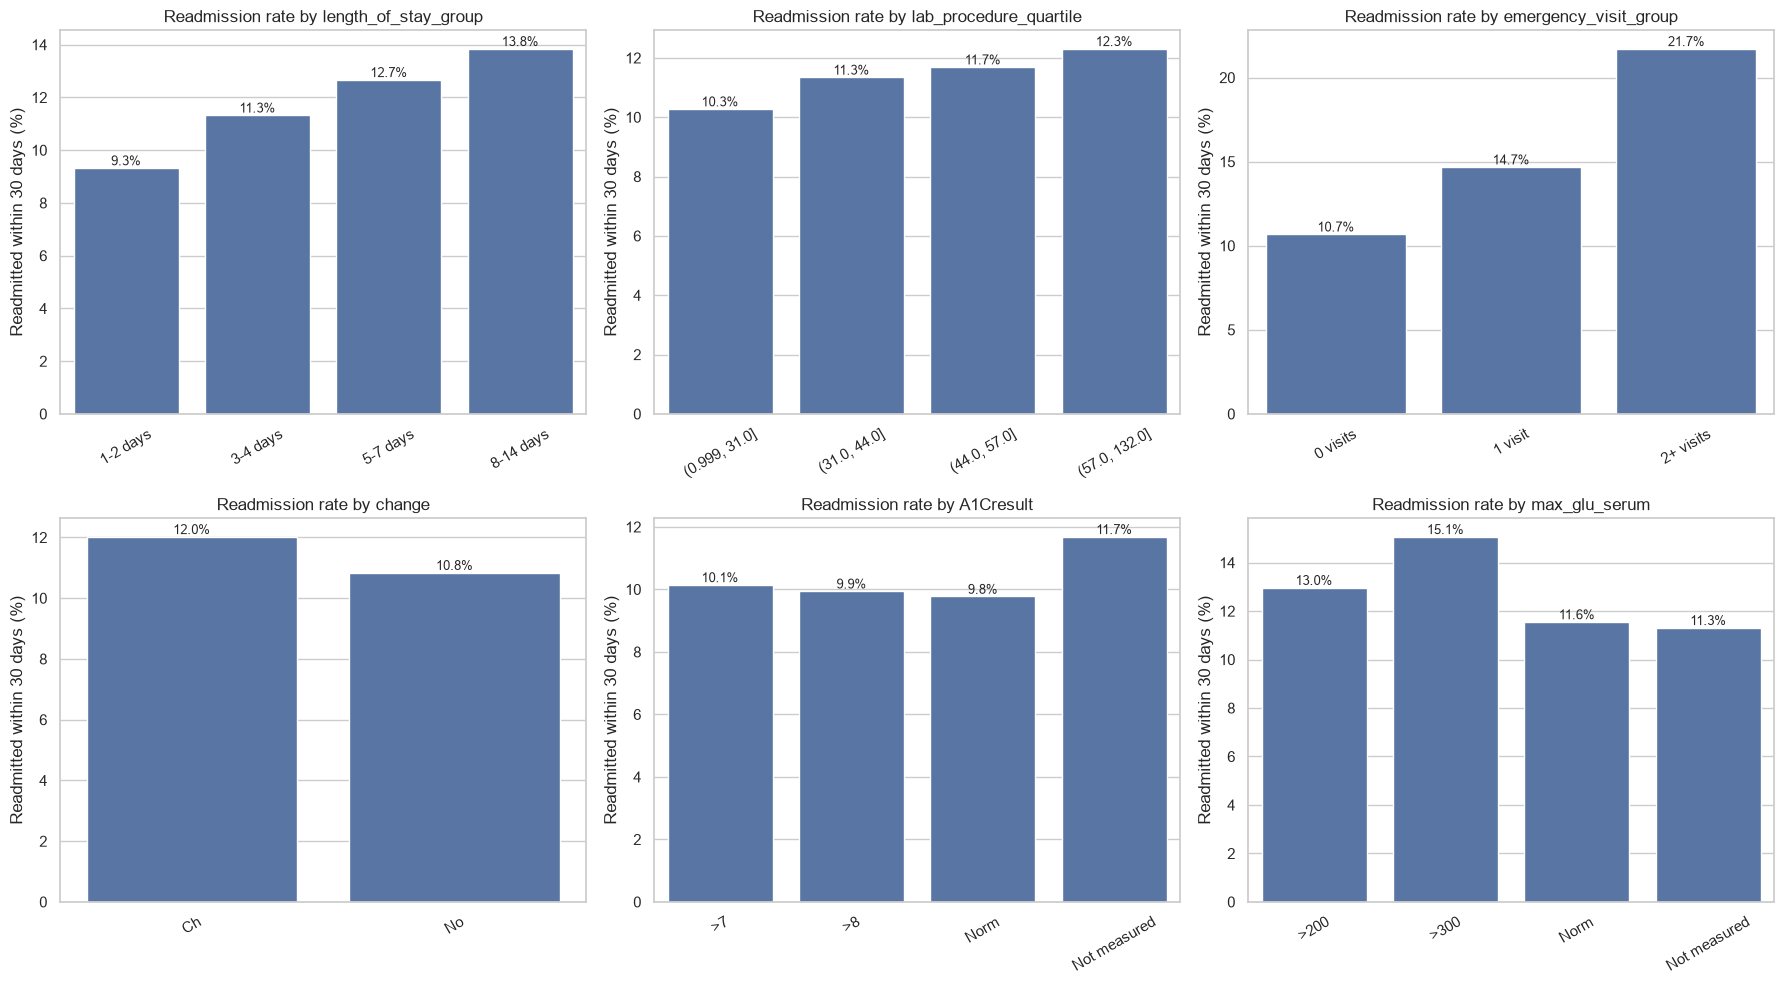

In [9]:
# Phase 2: Exploratory data analysis
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import chi2_contingency

sns.set_theme(style='whitegrid')
eda_df = df.copy()
eda_df['length_of_stay_group'] = pd.cut(
    eda_df['time_in_hospital'], bins=[0, 2, 4, 7, 14],
    labels=['1-2 days', '3-4 days', '5-7 days', '8-14 days'], include_lowest=True
)
eda_df['lab_procedure_quartile'] = pd.qcut(
    eda_df['num_lab_procedures'], q=4, duplicates='drop'
)
eda_df['emergency_visit_group'] = pd.cut(
    eda_df['number_emergency'], bins=[-1, 0, 1, float('inf')],
    labels=['0 visits', '1 visit', '2+ visits']
)
eda_df['A1Cresult'] = eda_df['A1Cresult'].fillna('Not measured')
eda_df['max_glu_serum'] = eda_df['max_glu_serum'].fillna('Not measured')

analysis_columns = [
    'length_of_stay_group', 'lab_procedure_quartile', 'emergency_visit_group',
    'change', 'A1Cresult', 'max_glu_serum'
]

# Statistical tests assess association, not causation.
for column in analysis_columns:
    contingency_table = pd.crosstab(eda_df[column], eda_df['readmitted'])
    _, p_value, _, _ = chi2_contingency(contingency_table)
    print(f'{column}: chi-square p-value = {p_value:.4g}')

fig, axes = plt.subplots(2, 3, figsize=(18, 10))
for ax, column in zip(axes.flat, analysis_columns):
    readmission_rate = (
        eda_df.groupby(column, observed=True)['readmitted'].mean()
        .mul(100).sort_index()
    )
    sns.barplot(x=readmission_rate.index.astype(str), y=readmission_rate.values, ax=ax, color='#4C72B0')
    ax.set_title(f'Readmission rate by {column}')
    ax.set_xlabel('')
    ax.set_ylabel('Readmitted within 30 days (%)')
    ax.tick_params(axis='x', rotation=30)
    for bar, rate in zip(ax.patches, readmission_rate.values):
        ax.annotate(f'{rate:.1f}%', (bar.get_x() + bar.get_width() / 2, rate),
                    ha='center', va='bottom', fontsize=9)

plt.tight_layout()
plt.show()


In [10]:
import pandas as pd
import numpy as np

# Assuming df is your cleaned DataFrame from Phase 1 and 2
print(f"Starting shape before Feature Engineering: {df.shape}")

# ==========================================
# 1. Service Utilization Index
# ==========================================
# Combine historical outpatient, emergency, and inpatient visits into a single score
# We can weight inpatient and emergency visits higher due to acute severity, or sum them.
df['service_utilization_index'] = (
    df['number_outpatient'] + 
    df['number_emergency'] * 2 +  # Higher weight for emergency visits
    df['number_inpatient'] * 3    # Highest weight for inpatient hospitalizations
)

print("-> Created 'service_utilization_index'")


# ==========================================
# 2. Polypharmacy Indicator
# ==========================================
# The Diabetes 130-US hospitals dataset typically contains columns for various medications 
# (e.g., metformin, repaglinide, insulin, etc.) coded as 'No', 'Up', 'Down', 'Steady'.
# First, identify the medication columns (adjust the list or filter based on your dataset schema)
medication_cols = [
    'metformin', 'repaglinide', 'nateglinide', 'chlorpropamide', 'glimepiride',
    'acetohexamide', 'glipizide', 'glyburide', 'tolbutamide', 'pioglitazone',
    'rosiglitazone', 'acarbose', 'miglitol', 'troglitazone', 'tolazamide',
    'examide', 'citoglipton', 'insulin', 'glyburide-metformin', 'glipizide-metformin',
    'glimepiride-pioglitazone', 'metformin-rosiglitazone', 'metformin-pioglitazone'
]

# Ensure we only use columns that actually exist in the dataframe
existing_meds = [col for col in medication_cols if col in df.columns]

# Count distinct medications where the patient was actively taking something other than 'No'
df['polypharmacy_count'] = df[existing_meds].apply(
    lambda row: sum(1 for val in row if val not in ['No', 'NO', np.nan]), axis=1
)

print(f"-> Created 'polypharmacy_count' across {len(existing_meds)} medication columns.")


# ==========================================
# 3. Comorbidity Count (ICD-9 Mapping)
# ==========================================
# ICD-9 diagnosis codes in this dataset (diag_1, diag_2, diag_3) can start with V or E, 
# or be numeric ranges representing disease categories.
def categorize_icd9(code):
    """Maps an ICD-9 code string to a broad clinical diagnostic category."""
    if pd.isna(code):
        return 'Unknown'
    
    code_str = str(code).strip()
    
    # Handle V and E codes separately if needed, or group by prefix ranges
    if code_str.startswith('V'):
        return 'Supplementary'
    if code_str.startswith('E'):
        return 'External_Causes'
    
    try:
        # Extract the numeric prefix (before the decimal point)
        float_val = float(code_str.split('.')[0])
    except ValueError:
        return 'Other'
    
    if 1 <= float_val <= 139:
        return 'Infectious'
    elif 140 <= float_val <= 239:
        return 'Neoplasms'
    elif 240 <= float_val <= 279:
        return 'Endocrine_Nutritional_Metabolic'
    elif 280 <= float_val <= 289:
        return 'Blood'
    elif 290 <= float_val <= 319:
        return 'Mental'
    elif 320 <= float_val <= 389:
        return 'Nervous'
    elif 390 <= float_val <= 459:
        return 'Circulatory'
    elif 460 <= float_val <= 519:
        return 'Respiratory'
    elif 520 <= float_val <= 579:
        return 'Digestive'
    elif 580 <= float_val <= 629:
        return 'Genitourinary'
    elif 630 <= float_val <= 679:
        return 'Pregnancy'
    elif 680 <= float_val <= 709:
        return 'Skin'
    elif 710 <= float_val <= 739:
        return 'Musculoskeletal'
    elif 740 <= float_val <= 759:
        return 'Congenital'
    elif 760 <= float_val <= 779:
        return 'Perinatal'
    elif 780 <= float_val <= 799:
        return 'Symptoms_Signs_Ill_Defined'
    elif 800 <= float_val <= 999:
        return 'Injury_Poisoning'
    else:
        return 'Other'

# Apply mapping to primary diagnosis (diag_1) and create a comorbidity burden count
df['primary_diag_category'] = df['diag_1'].apply(categorize_icd9)

# Comorbidity count: Count how many distinct major clinical categories are affected across diag_1, diag_2, diag_3
diag_columns = [col for col in ['diag_1', 'diag_2', 'diag_3'] if col in df.columns]
df['comorbidity_count'] = df[diag_columns].apply(
    lambda row: len(set(categorize_icd9(val) for val in row if pd.notna(val) and categorize_icd9(val) != 'Unknown')), 
    axis=1
)

print("-> Created 'primary_diag_category' and 'comorbidity_count'")


# ==========================================
# 4. Encoding Categorical Features
# ==========================================
# Select categorical columns to encode (e.g., admission_type_id, primary_diag_category, etc.)
categorical_to_encode = ['admission_type_id', 'primary_diag_category']
existing_cats = [col for col in categorical_to_encode if col in df.columns]

# One-Hot Encoding
df = pd.get_dummies(df, columns=existing_cats, drop_first=True, dtype=int)

print(f"-> One-Hot Encoded categories: {existing_cats}")
print(f"Final shape after Feature Engineering: {df.shape}")

Starting shape before Feature Engineering: (99343, 50)
-> Created 'service_utilization_index'
-> Created 'polypharmacy_count' across 23 medication columns.
-> Created 'primary_diag_category' and 'comorbidity_count'
-> One-Hot Encoded categories: ['admission_type_id', 'primary_diag_category']
Final shape after Feature Engineering: (99343, 77)


Features shape (X): (99343, 71)
Target distribution (y):
readmitted
0    0.886112
1    0.113888
Name: proportion, dtype: float64
Training set shape: (79474, 38)
Test set shape: (19869, 38)
-> Random Forest model trained successfully!

--- Classification Report ---
              precision    recall  f1-score   support

           0       0.92      0.70      0.79     17606
           1       0.19      0.54      0.28      2263

    accuracy                           0.68     19869
   macro avg       0.55      0.62      0.53     19869
weighted avg       0.84      0.68      0.73     19869

ROC-AUC Score: 0.6659


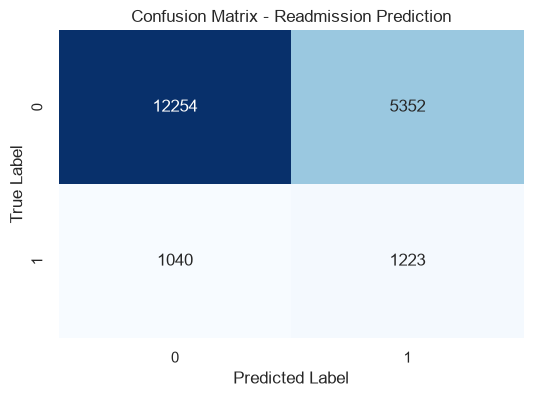


--- Top 10 Most Important Features ---
                      Feature  Importance
10  service_utilization_index    0.157926
8            number_inpatient    0.156345
0    discharge_disposition_id    0.117501
3          num_lab_procedures    0.081663
5             num_medications    0.076256
2            time_in_hospital    0.062773
9            number_diagnoses    0.047961
4              num_procedures    0.036526
11         polypharmacy_count    0.032169
7            number_emergency    0.030220


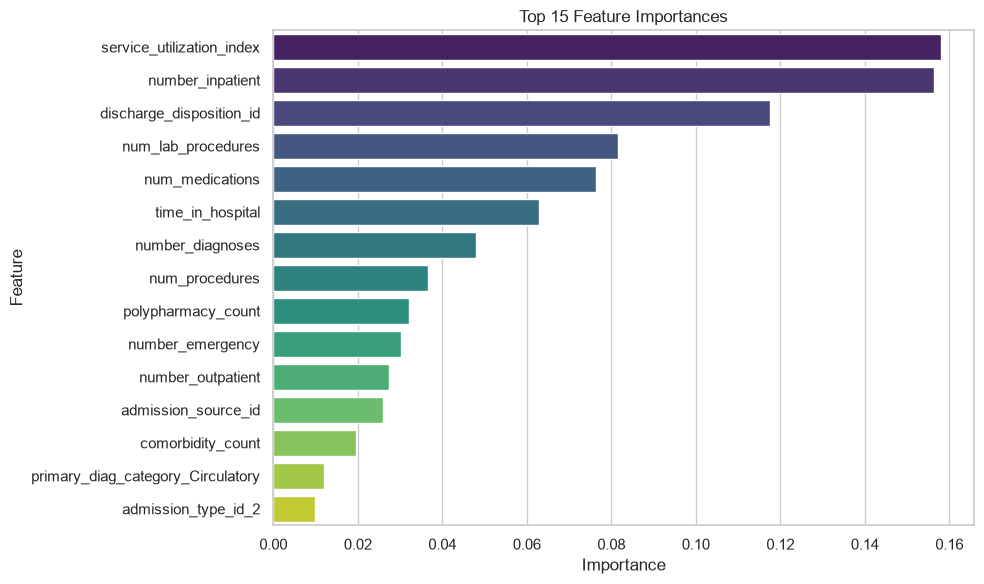

In [11]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score, roc_curve
import matplotlib.pyplot as plt
import seaborn as sns

# ==========================================
# 1. Prepare Data for Modeling
# ==========================================
# Drop non-feature columns (like original ID strings, raw text dates, or unencoded high-cardinality objects)
# Adjust the drop list based on what columns remain in your df
drop_cols = ['encounter_id', 'patient_nbr', 'diag_1', 'diag_2', 'diag_3', 'readmitted']
features_to_drop = [col for col in drop_cols if col in df.columns]

X = df.drop(columns=features_to_drop)
y = df['readmitted'] # Binary target created in Phase 1 (1 = <30 days, 0 = >30 days or NO)

print(f"Features shape (X): {X.shape}")
print(f"Target distribution (y):\n{y.value_counts(normalize=True)}")

# Ensure all columns are numeric (Random Forest requires numeric data)
X = X.select_dtypes(include=[np.number])

# Train-Test Split (Stratified to maintain the class balance of readmissions)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print(f"Training set shape: {X_train.shape}")
print(f"Test set shape: {X_test.shape}")


# ==========================================
# 2. Train Random Forest Classifier
# ==========================================
# class_weight='balanced' helps handle the class imbalance typical in readmission data
rf_model = RandomForestClassifier(
    n_estimators=100,
    max_depth=12,
    min_samples_split=10,
    class_weight='balanced',
    random_state=42,
    n_jobs=-1
)

rf_model.fit(X_train, y_train)
print("-> Random Forest model trained successfully!")


# ==========================================
# 3. Model Evaluation & Metrics
# ==========================================
# Predictions
y_pred = rf_model.predict(X_test)
y_prob = rf_model.predict_proba(X_test)[:, 1]

# Classification Report
print("\n--- Classification Report ---")
print(classification_report(y_test, y_pred))

# ROC-AUC Score
roc_auc = roc_auc_score(y_test, y_prob)
print(f"ROC-AUC Score: {roc_auc:.4f}")

# Confusion Matrix Plot
plt.figure(figsize=(6, 4))
cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False)
plt.title('Confusion Matrix - Readmission Prediction')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.show()


# ==========================================
# 4. Feature Importance Analysis
# ==========================================
# Check if your engineering efforts (like service_utilization_index) paid off
feature_importances = pd.DataFrame({
    'Feature': X_train.columns,
    'Importance': rf_model.feature_importances_
}).sort_values(by='Importance', ascending=False)

print("\n--- Top 10 Most Important Features ---")
print(feature_importances.head(10))

# Plot top 15 features
plt.figure(figsize=(10, 6))
sns.barplot(
    x='Importance', 
    y='Feature', 
    data=feature_importances.head(15), 
    palette='viridis',
    hue='Feature',
    legend=False
)
plt.title('Top 15 Feature Importances')
plt.tight_layout()
plt.show()

In [12]:
from sklearn.model_selection import RandomizedSearchCV

# Define the hyperparameter grid
param_dist = {
    'n_estimators': [100, 200, 300],
    'max_depth': [8, 12, 16, None],
    'min_samples_split': [5, 10, 20],
    'min_samples_leaf': [2, 4, 8],
    'class_weight': ['balanced', 'balanced_subsample']
}

# Setup Randomized Search
random_search = RandomizedSearchCV(
    estimator=RandomForestClassifier(random_state=42, n_jobs=-1),
    param_distributions=param_dist,
    n_iter=10,
    cv=3,
    scoring='roc_auc',
    random_state=42,
    n_jobs=-1
)

random_search.fit(X_train, y_train)

print("Best Hyperparameters found:")
print(random_search.best_params_)

# Use the best model for the next phases
best_rf_model = random_search.best_estimator_

Best Hyperparameters found:
{'n_estimators': 200, 'min_samples_split': 5, 'min_samples_leaf': 8, 'max_depth': 16, 'class_weight': 'balanced'}


In [ ]:
import shap

# Initialize the SHAP Tree Explainer using our best model
explainer = shap.TreeExplainer(best_rf_model)
shap_values = explainer(X_test)

# Summary Plot (Beeswarm plot showing feature impact vs value)
plt.figure(figsize=(10, 6))
shap.summary_plot(shap_values, X_test, plot_type="dot")
plt.title("SHAP Feature Impact on Readmission Risk")
plt.show()

# Bar plot of mean absolute SHAP values (overall feature importance)
plt.figure(figsize=(10, 6))
shap.summary_plot(shap_values, X_test, plot_type="bar")
plt.show()